In [3]:
from IPython.display import display, HTML
from IPython.core.interactiveshell import InteractiveShell
display(HTML("<style>.container { width:98% !important; }</style>"))
%load_ext autoreload  
%autoreload 2
InteractiveShell.ast_node_interactivity = "all"

In [4]:
import numpy as np
import cv2
import pysift
from matplotlib import pyplot as plt
import logging
logger = logging.getLogger(__name__)


In [5]:
from numpy import (all, any, array, arctan2, cos, sin, exp, dot, log, 
                    logical_and, roll, sqrt, stack, trace, unravel_index, pi, 
                    deg2rad, rad2deg, where, zeros, floor, full, nan, isnan, round, float32)
from numpy.linalg import det, lstsq, norm

from cv2 import resize, GaussianBlur, subtract, KeyPoint, INTER_LINEAR, INTER_NEAREST
from functools import cmp_to_key
import logging

In [6]:
from pysift import  generateBaseImage

In [7]:
img1 = cv2.imread('box.png', 0)           # queryImage
img2 = cv2.imread('box_in_scene.png', 0)  # trainImage
img1.shape, img1.dtype

((223, 324), dtype('uint8'))

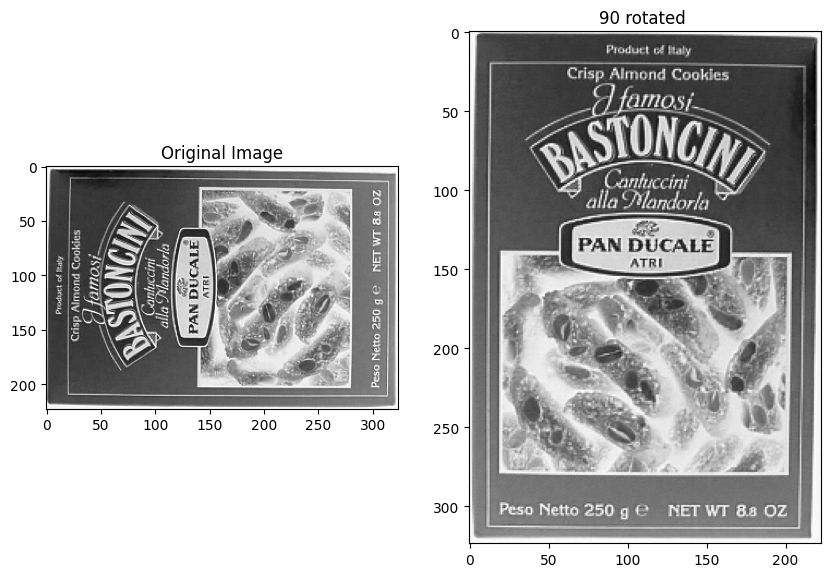

In [8]:
img1_rotated = cv2.rotate(img1, cv2.ROTATE_90_CLOCKWISE)
plt.figure(figsize=[10,10])   ##, cmap='Grays'
plt.subplot(121);plt.imshow(img1,cmap='Grays');plt.title("Original Image");
plt.subplot(122);plt.imshow(img1_rotated,cmap='Grays');plt.title(f"90 rotated ");

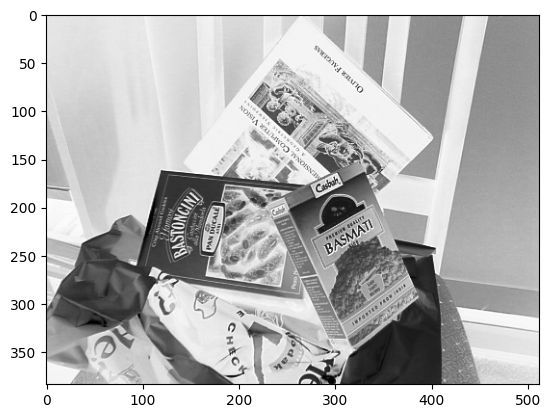

In [9]:
plt.imshow(img2, cmap='Grays')

In [10]:

sigma = 1.6
assumed_blur = 0.5
num_intervals = 3
image_border_width=5


## Steps:

**`computeKeypointsAndDescriptors(image, sigma=1.6, num_intervals=3, assumed_blur=0.5, image_border_width=5)`**

Compute SIFT keypoints and descriptors for an input image



    computeKeypointsAndDescriptors(image, sigma=1.6, num_intervals=3, assumed_blur=0.5, image_border_width=5):
        """
        Compute SIFT keypoints and descriptors for an input image
        """
        image = image.astype('float32')
        base_image = generateBaseImage(image, sigma, assumed_blur)
        num_octaves = computeNumberOfOctaves(base_image.shape)
        gaussian_kernels = generateGaussianKernels(sigma, num_intervals)
        gaussian_images = generateGaussianImages(base_image, num_octaves, gaussian_kernels)
        dog_images = generateDoGImages(gaussian_images)
        keypoints = findScaleSpaceExtrema(gaussian_images, dog_images, num_intervals, sigma, image_border_width)
        keypoints = removeDuplicateKeypoints(keypoints)
        keypoints = convertKeypointsToInputImageSize(keypoints)
        descriptors = generateDescriptors(keypoints, gaussian_images)
        return keypoints, descriptors


-    base_image       = `generateBaseImage`(image, sigma, assumed_blur)
-    num_octaves      = `computeNumberOfOctaves`(base_image.shape)
-    gaussian_kernels = `generateGaussianKernels`(sigma, num_intervals)
-    gaussian_images  = `generateGaussianImages`(base_image, num_octaves, gaussian_kernels)
-    dog_images       = `generateDoGImages`(gaussian_images)
-    keypoints        = `findScaleSpaceExtrema`(gaussian_images, dog_images, num_intervals, sigma, image_border_width)
-    keypoints        = `removeDuplicateKeypoints`(keypoints)
-    keypoints        = `convertKeypointsToInputImageSize`(keypoints)
-    descriptors      = `generateDescriptors`(keypoints, gaussian_images)

## Generate Base Image

 `generateBaseImage()` Doubles the input image in size and applies Gaussian blur. Assuming the input image has a blur of `assumed_blur = 0.5`, if we want our resulting base image to have a blur of `sigma`, we need to blur the doubled input image by `sigma_diff`. Note that blurring an input image by kernel size σ₁ and then blurring the resulting image by σ₂ is equivalent to blurring the input image just once by σ, where σ² = σ₁² + σ₂² . Therefore  `σ₂ = sqrt(σ²  - σ₁²)` 

In [11]:
def generateBaseImage(image, sigma, assumed_blur):
    """
    Generate base image from input image by upsampling by 2 in both directions and blurring
    """
    logger.debug('Generating base image...')
    print(f" original image: {image.shape}")
    image = resize(image, (0, 0), fx=2, fy=2, interpolation=INTER_LINEAR)
    print(f" resized image : {image.shape}")
    sigma_diff = sqrt(max((sigma ** 2) - ((2 * assumed_blur) ** 2), 0.01))
    print(f" sigma diff    : {sigma_diff:.4f}")
    return GaussianBlur(image, (0, 0), sigmaX=sigma_diff, sigmaY=sigma_diff), sigma_diff  # the image blur is now sigma instead of assumed_blur

In [12]:
image = img1.astype('float32')
base_image, sigma_diff = generateBaseImage(image, sigma, assumed_blur)

 original image: (223, 324)
 resized image : (446, 648)
 sigma diff    : 1.2490


In [13]:
print(f" base_image: {type(base_image)}-{base_image.dtype}   shape: {base_image.shape}")

 base_image: <class 'numpy.ndarray'>-float32   shape: (446, 648)


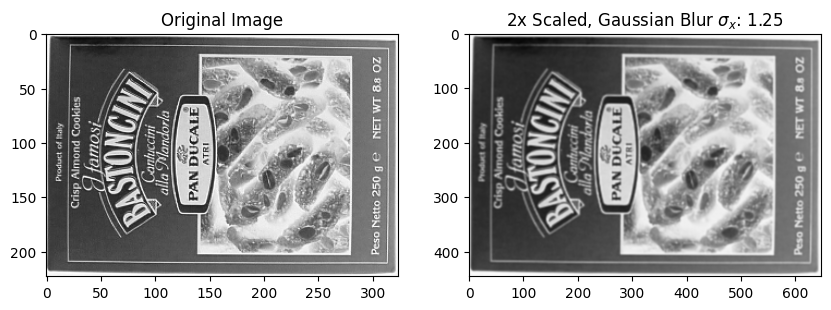

In [14]:
plt.figure(figsize=[10,10])
plt.subplot(121);plt.imshow(img1, cmap='Grays');plt.title("Original Image");
plt.subplot(122);plt.imshow(base_image, cmap='Grays');plt.title(f"2x Scaled, Gaussian Blur $\sigma_x$: {sigma_diff:.2f} ");


## Compute number of Octaves

This function computes the number of times we can repeatedly halve an image until it becomes too small. 

For starters, the final image should have a side length of at least 1 pixel. 
If y is the shorter side length of the image, then we have y / 2^x = 1, where x is the number of times we can halve the base image. We can take the logarithm of both sides and solve for x to obtain log(y) / log(2). So why does the -1 show up in the function above? At the end of the day, we have to round x down to the nearest integer (floor(x)) to have an integer number of layers in our image pyramid.

In [15]:
def computeNumberOfOctaves(image_shape):
    """Compute number of octaves in image pyramid as function of base image shape (OpenCV default)
    log2(min(imageshape)
    """
    print(f" min image_shape: {min(image_shape)}  log2({min(image_shape)}): {np.log2(min(image_shape)):.4f}    ")
    print(f" (log2({min(image_shape)}) - 1): {(np.log2(min(image_shape)) - 1):.4f}  final: {round(np.log2(min(image_shape))  - 1)}")
    # return int(round(  log(min(image_shape)) / log(2) - 1))
    # return int(round( np.log2(min(image_shape)) - 1))
    return int(floor(np.log2(min(image_shape))))

In [16]:
num_octaves = computeNumberOfOctaves(base_image.shape)

 min image_shape: 446  log2(446): 8.8009    
 (log2(446) - 1): 7.8009  final: 8.0


In [17]:
print(f"num_octaves:  {num_octaves}")

num_octaves:  8


## Generate Gaussian Kernels

`generateGaussianKernels()` Creates a list of the amount of blur for each image in a particular layer. 

- Note that the image pyramid has `numOctaves` layers, but each layer itself has `numIntervals + 3` images. All the images in the same layer have the same width and height, but the amount of blur successively increases.

- Where does the `+ 3` come from? We have `numIntervals + 1` images to cover `numIntervals` steps from one blur value to twice that value. We have another `+ 2` for one blur step before the first image in the layer and another blur step after the last image in the layer.

We need these **two extra images at the end** because we’ll subtract adjacent Gaussian images to create a DoG image pyramid. This means that if we compare images from two neighboring layers, we’ll see many of the same blur values repeated. We need this repetition to make sure we cover all blur steps when we subtract images. 

In [18]:
def generateGaussianKernels(sigma, num_intervals):
    """
    Generate list of gaussian kernels at which to blur the input image. Default values of sigma, intervals, and octaves follow section 3 of Lowe's paper.
    """
    logger.debug('Generating scales...')
    num_images_per_octave = num_intervals + 3
    k = 2 ** (1. / num_intervals)
    print(f"num_images_per_octave : {num_images_per_octave}     k: {k:.3f}")
    gaussian_kernels = zeros(num_images_per_octave)  # scale of gaussian blur necessary to go from one blur scale to the next within an octave
    print(f"gaussian_kernels      : {gaussian_kernels}\n")
    gaussian_kernels[0] = sigma
    
    # sigma_previous = 1
    # sigma_total = k * sigma_previous
    # print(f" sigma_total ({k:.3f} * {sigma_previous:.3f}): {sigma_total:.3f}     sigma_previous: {sigma_previous:.3f}      "
    #           f"  sqrt(sigma_total^2 - sigma_previous^2): {sqrt(sigma_total ** 2 - sigma_previous ** 2):.3f}")
    
    for image_index in range(1, num_images_per_octave):
        sigma_previous = (k ** (image_index - 1)) * sigma
        sigma_total = k * sigma_previous
        print(f" index: {image_index} - sigma_total ({k:.3f} * {sigma_previous:.3f}): {sigma_total:.3f}     sigma_previous (({k:.3f} ** {(image_index - 1)}) * {sigma}): {sigma_previous:.3f}      "
              f" sigma sqrt(sigma_total^2 - sigma_previous^2): {sqrt(sigma_total ** 2 - sigma_previous ** 2):.3f}")
        gaussian_kernels[image_index] = sqrt(sigma_total ** 2 - sigma_previous ** 2)
    print(f"\ngaussian_kernels      : {np.round(gaussian_kernels,3)}")
    return gaussian_kernels

In [19]:
gaussian_kernels = generateGaussianKernels(sigma, num_intervals)

# print(effective_sigma)

num_images_per_octave : 6     k: 1.260
gaussian_kernels      : [0. 0. 0. 0. 0. 0.]

 index: 1 - sigma_total (1.260 * 1.600): 2.016     sigma_previous ((1.260 ** 0) * 1.6): 1.600       sigma sqrt(sigma_total^2 - sigma_previous^2): 1.226
 index: 2 - sigma_total (1.260 * 2.016): 2.540     sigma_previous ((1.260 ** 1) * 1.6): 2.016       sigma sqrt(sigma_total^2 - sigma_previous^2): 1.545
 index: 3 - sigma_total (1.260 * 2.540): 3.200     sigma_previous ((1.260 ** 2) * 1.6): 2.540       sigma sqrt(sigma_total^2 - sigma_previous^2): 1.947
 index: 4 - sigma_total (1.260 * 3.200): 4.032     sigma_previous ((1.260 ** 3) * 1.6): 3.200       sigma sqrt(sigma_total^2 - sigma_previous^2): 2.453
 index: 5 - sigma_total (1.260 * 4.032): 5.080     sigma_previous ((1.260 ** 4) * 1.6): 4.032       sigma sqrt(sigma_total^2 - sigma_previous^2): 3.090

gaussian_kernels      : [1.6   1.226 1.545 1.947 2.453 3.09 ]


In [20]:
# effective_sigma = []
# prev_blur = 0.5
# for i in [0,1,2,3,4]:
#     effective_sigma[i] = sigma * (sqrt(2) ** i)
# print(f" sigma: {sigma}  i: {i}   kernel: {effective_sigma[i]}")

In [21]:
greek_letterz={code:chr(code) for code in range(945,970)}

print(greek_letterz)

{945: 'α', 946: 'β', 947: 'γ', 948: 'δ', 949: 'ε', 950: 'ζ', 951: 'η', 952: 'θ', 953: 'ι', 954: 'κ', 955: 'λ', 956: 'μ', 957: 'ν', 958: 'ξ', 959: 'ο', 960: 'π', 961: 'ρ', 962: 'ς', 963: 'σ', 964: 'τ', 965: 'υ', 966: 'φ', 967: 'χ', 968: 'ψ', 969: 'ω'}


**gaussian_kernels      : [1.6   1.226 1.545 1.947 2.453 3.09 ]**

The first element of this array is simply our starting sigma, but after that each element is the additional scale we need to convolve with the previous scale. 

To be concrete, we start out with an image with scale 1.6. 

- We blur this image with a Gaussian kernel of size 1.22627 to produce the second image with a blur of `sqrt(1.6 ** 2 + 1.22627 ** 2) == 2.01587`
- We blur this image with a Gaussian kernel of size 1.54501 to produce a third image of blur `sqrt(2.01587 ** 2 + 1.54501 ** 2) == 2.53984`.
- Finally, we blur this image with a Gaussian kernel of size 1.94659 to produce our last image, which has a blur of `sqrt(2.53984 ** 2 + 1.94659 ** 2) == 3.2`.

- But 2 * 1.6 == 3.2, so we’ve moved up exactly one octave!

## Generate Gaussian Images

We `generateGaussianImages()` by starting with our base image and successively blurring it according to our gaussian_kernels. 

Note that we skip the first element of gaussian_kernels because we begin with an image that already has that blur value. We halve the third-to-last image, since this has the appropriate blur we want, and use this to begin the next layer. 

This way we get that nice overlap mentioned previously. 


In [59]:

def generateGaussianImages(image, num_octaves, gaussian_kernels):
    """Generate scale-space pyramid of Gaussian images
    """
    logger.debug('Generating Gaussian images...')

    gaussian_images = []
    print(f" Gaussian kernel: {gaussian_kernels}  ")

    for octave_index in range(num_octaves):
        gaussian_images_in_octave = []
        gaussian_images_in_octave.append(image)  # first image in octave already has the correct blur
        print(f" [octave_index: {octave_index}] \t image size: {image.shape}")
        
        for idx, gaussian_kernel in enumerate(gaussian_kernels[1:]):
            image = GaussianBlur(image, (0, 0), sigmaX=gaussian_kernel, sigmaY=gaussian_kernel)
            gaussian_images_in_octave.append(image)
            # print(f"  \tkernel {idx+1} -> Gaussian kernel: {gaussian_kernel: .3f}    image shape: {image.shape}")
        gaussian_images.append(gaussian_images_in_octave)
        octave_base = gaussian_images_in_octave[-3]
        # print(f"\t kernel[-3]: {gaussian_kernels[-3]:.3f}  octave_base size: {octave_base.shape}")
        
        image = resize(octave_base, (int(octave_base.shape[1] / 2), int(octave_base.shape[0] / 2)), interpolation=INTER_NEAREST)
        
        print(f"\t image shape for next octave:   {image.shape}")
    return array(gaussian_images, dtype=object)

In [60]:
print(f"num_octaves :  {num_octaves}      gaussian_kernels :  {gaussian_kernels}")

num_octaves :  8      gaussian_kernels :  [1.6        1.2262735  1.54500779 1.94658784 2.452547   3.09001559]


In [61]:
gaussian_images = generateGaussianImages(base_image, num_octaves, gaussian_kernels)

 Gaussian kernel: [1.6        1.2262735  1.54500779 1.94658784 2.452547   3.09001559]  
 [octave_index: 0] 	 image size: (446, 648)
	 image shape for next octave:   (223, 324)
 [octave_index: 1] 	 image size: (223, 324)
	 image shape for next octave:   (111, 162)
 [octave_index: 2] 	 image size: (111, 162)
	 image shape for next octave:   (55, 81)
 [octave_index: 3] 	 image size: (55, 81)
	 image shape for next octave:   (27, 40)
 [octave_index: 4] 	 image size: (27, 40)
	 image shape for next octave:   (13, 20)
 [octave_index: 5] 	 image size: (13, 20)
	 image shape for next octave:   (6, 10)
 [octave_index: 6] 	 image size: (6, 10)
	 image shape for next octave:   (3, 5)
 [octave_index: 7] 	 image size: (3, 5)
	 image shape for next octave:   (1, 2)


In [52]:
print(type(gaussian_images),  gaussian_images.shape[1], (gaussian_images.shape),  type(gaussian_images[0,0]), gaussian_images[0,0].shape)

<class 'numpy.ndarray'> 6 (8, 6) <class 'numpy.ndarray'> (446, 648)


## Display Gaussian Blurred Images


Finally, we `generateDoGImages()` by subtracting successive pairs of these Gaussian-blurred images. 

Careful — although ordinary subtraction will work here because we’ve cast the input image to float32, we’ll use OpenCV’s `subtract()` function so that the code won’t break if you choose to remove this cast and pass in uint type images.

In [31]:

def display_octave_images(gaussian_images, octave = 0):
    plt.figure(figsize=[20,10])
    NUM_KERNELS = gaussian_images.shape[1] 
    subplot = 100 + (10*NUM_KERNELS) + 1
    for i in range(NUM_KERNELS):
        imshape = gaussian_images[octave,i].shape
        _ = plt.subplot(subplot);_ = plt.imshow(gaussian_images[octave,i], cmap='binary');_ = plt.title(f"Octive: {octave} {imshape} Krnl: {gaussian_kernels[i]:.2f}", fontsize=8);
        subplot += 1
        # plt.subplot(122);plt.imshow(base_image, cmap='Grays');plt.title(f"2x Scaled, Gaussian Blur $\sigma_x$: {sigma_diff:.2f} ");
    plt.show()

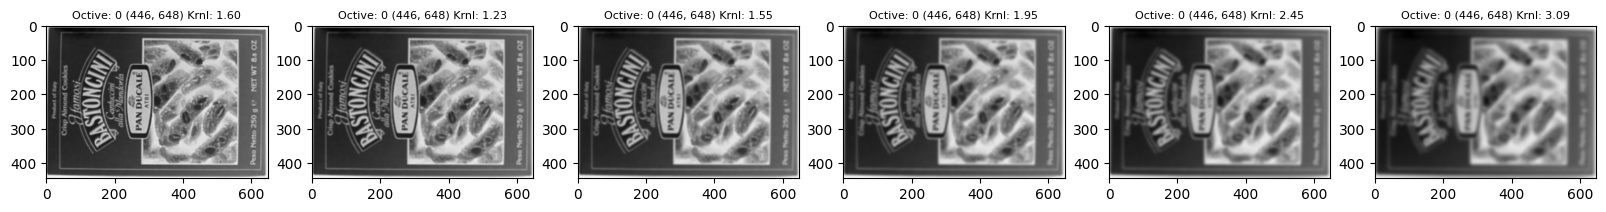

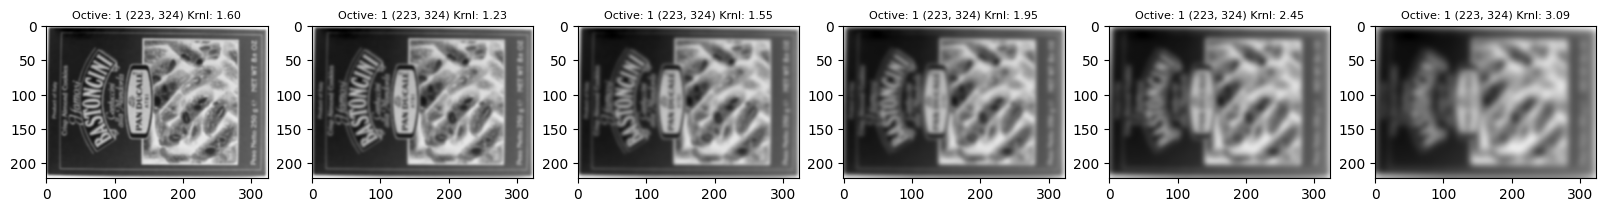

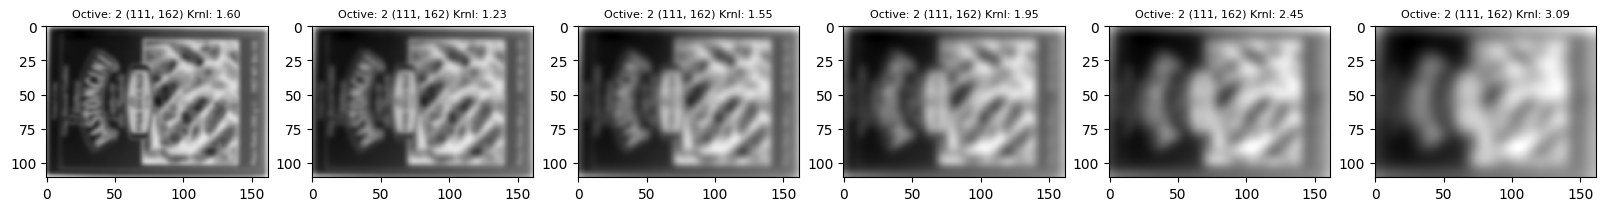

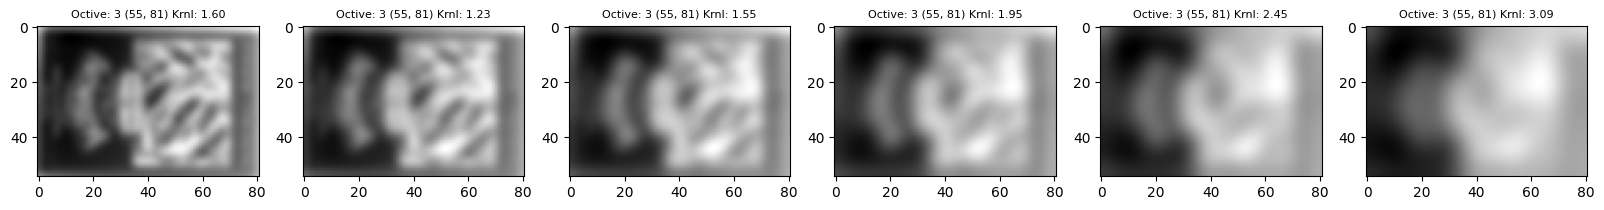

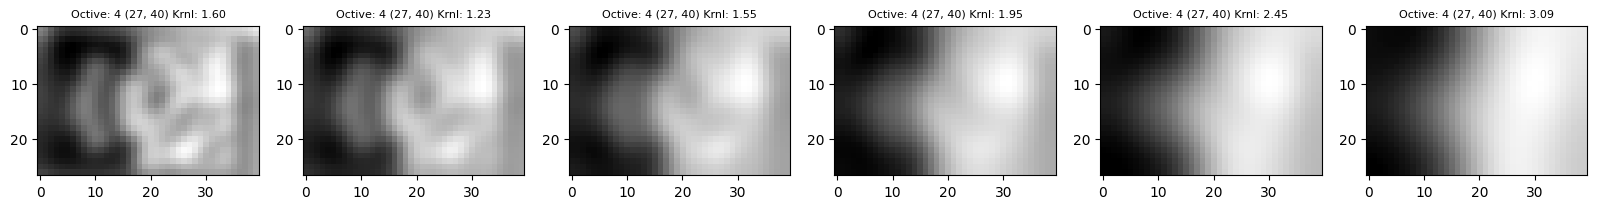

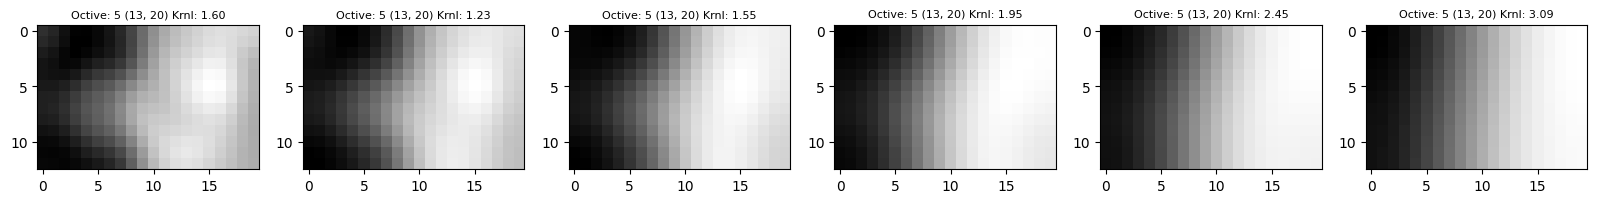

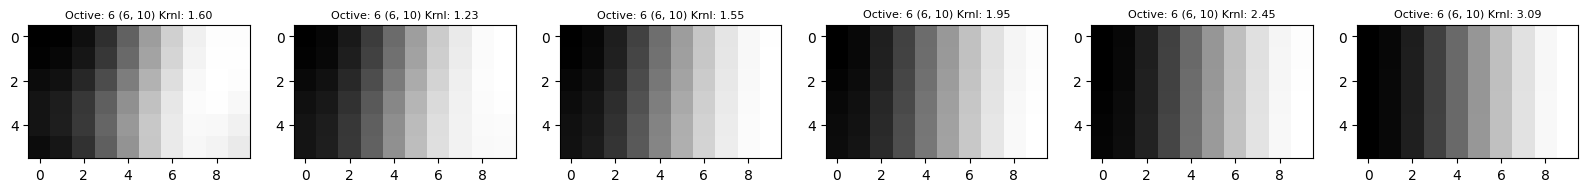

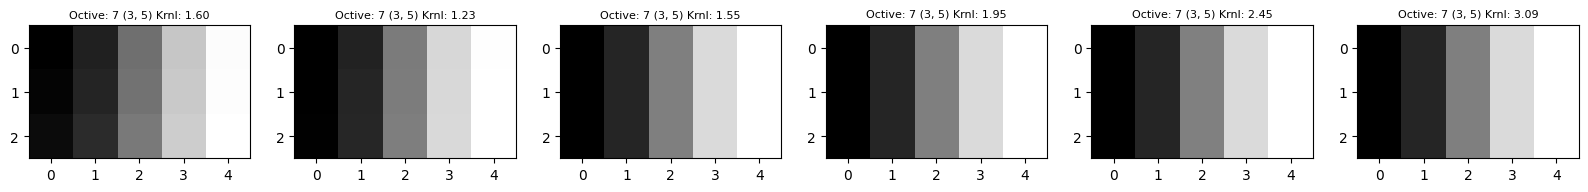

In [32]:
for octave in range(num_octaves):
    display_octave_images(gaussian_images, octave= octave)


## Generate DoG Images

In [62]:
def generateDoGImages(gaussian_images):
    """
    Generate Difference-of-Gaussians image pyramid
    """
    logger.debug('Generating Difference-of-Gaussian images...')
    dog_images = []

    for gaussian_images_in_octave in gaussian_images:
        dog_images_in_octave = []
        for first_image, second_image in zip(gaussian_images_in_octave, gaussian_images_in_octave[1:]):
            dog_images_in_octave.append(subtract(second_image, first_image))  # ordinary subtraction will not work because the images are unsigned integers
        dog_images.append(dog_images_in_octave)
    return array(dog_images, dtype=object)


In [75]:
def display_dog_images(dg_images, octave = 0, kernels = []):
    plt.figure(figsize=[20,10])
    NUM_KERNELS = dg_images.shape[1] 
    subplot = 100 + (10*NUM_KERNELS) + 1
    for i in range(NUM_KERNELS):
        _ = plt.subplot(subplot);
        _ = plt.imshow(dg_images[octave,i], cmap='Grays');
        _ = plt.title(f"{dg_images[octave,i].shape}    Oct: {octave} Krnls: ({kernels[i]:.3f}, {kernels[i+1]:.3f}) ", fontsize=7);
        subplot += 1
        # plt.subplot(122);plt.imshow(base_image, cmap='Grays');plt.title(f"2x Scaled, Gaussian Blur $\sigma_x$: {sigma_diff:.2f} ");
    plt.show()

In [76]:
dog_images = generateDoGImages(gaussian_images)

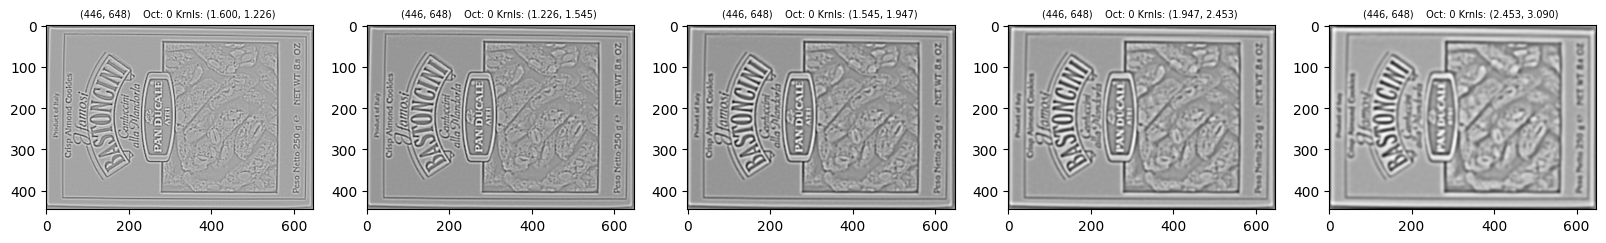

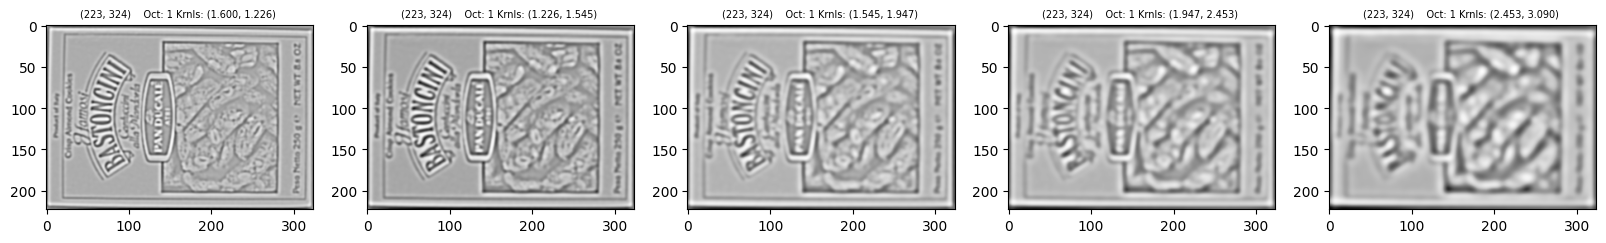

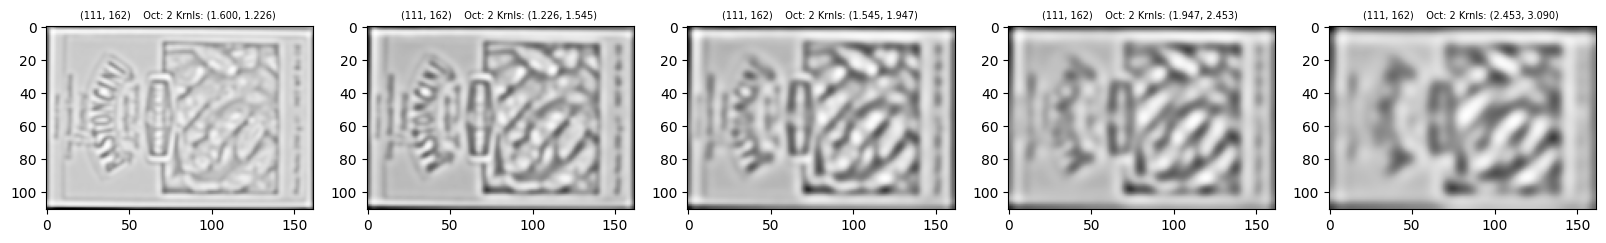

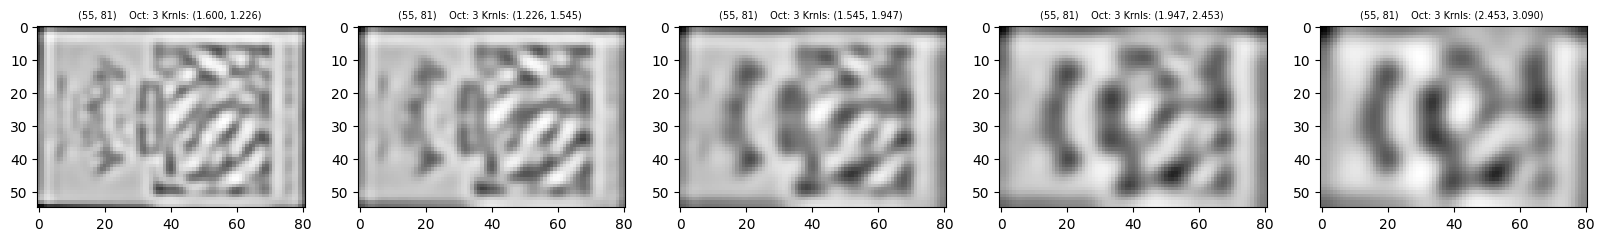

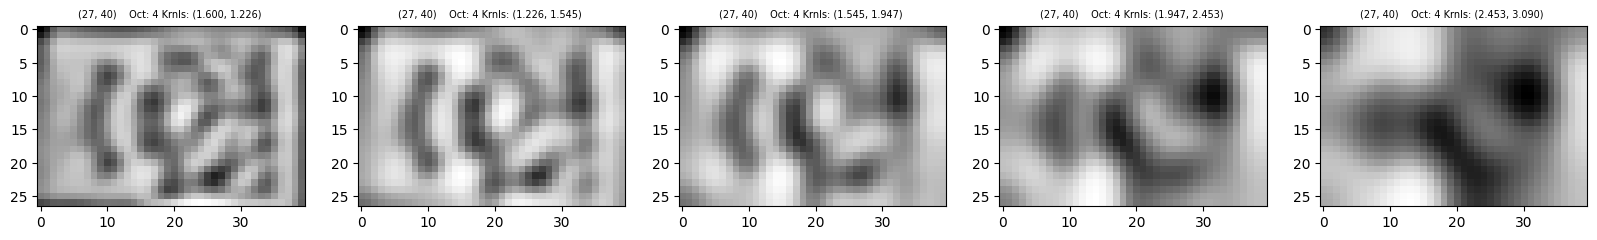

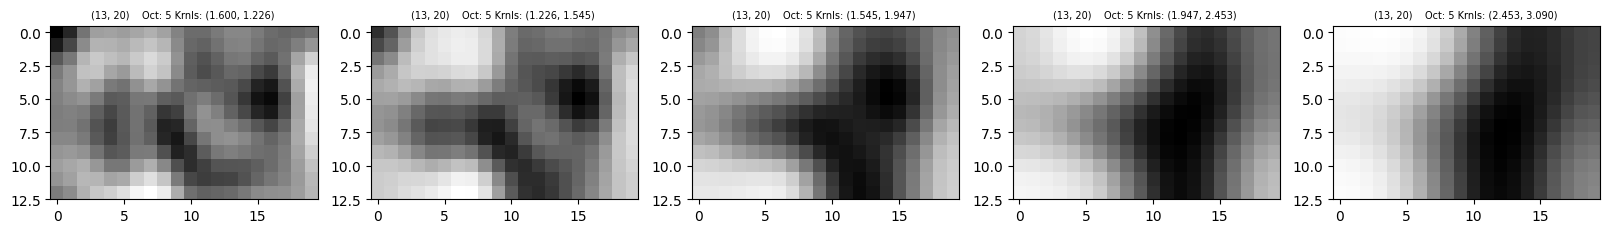

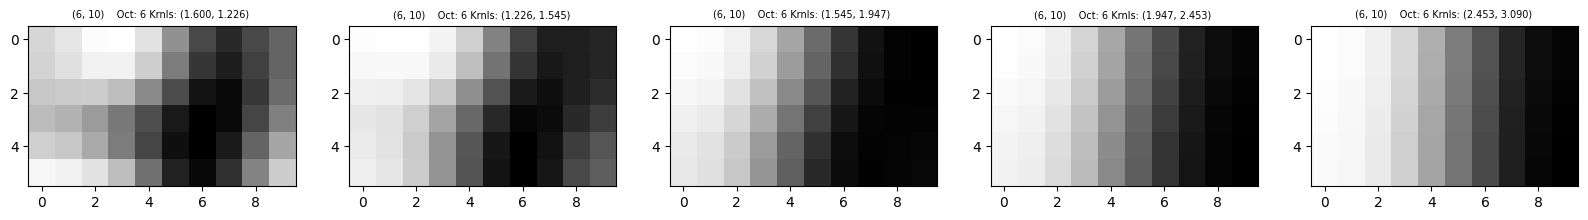

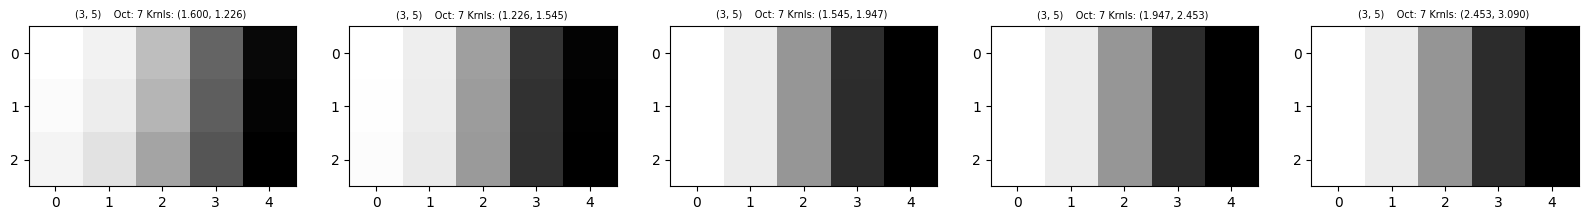

In [77]:
num_octaves = dog_images.shape[0]
for octave in range(num_octaves):
    display_dog_images(dog_images, octave= octave, kernels = gaussian_kernels)

## Find Scale Space Extrema

Here, we just iterate through each layer, taking three successive images at a time. 

Remember that all images in a layer have the same size — only their amounts of blur differ. In each triplet of images, we look for **pixels in the middle image that are greater than or less than all of their 26 neighbors: 8 neighbors in the middle image, 9 neighbors in the image below, and 9 neighbors in the image above**. 

The function `isPixelAnExtremum()` performs this check. These are our maxima and minima (strictly speaking, they include saddle points because we include pixels that are equal in value to all their neighbors). When we’ve found an extremum, we localize its position at the subpixel level along all three dimensions (width, height, and scale) using `localizeExtremumViaQuadraticFit()`, explained in more detail below.
    

In [78]:
from pysift import isPixelAnExtremum, localizeExtremumViaQuadraticFit, computeKeypointsWithOrientations
print(dog_images.shape)

(8, 5)


In [117]:
del findScaleSpaceExtrema

In [135]:
def findScaleSpaceExtrema(gaussian_images, dog_images, num_intervals, sigma, image_border_width, contrast_threshold=0.04):
    """Find pixel positions of all scale-space extrema in the image pyramid
    """
    logger.debug('Finding scale-space extrema...')
    print(f" gaussian images    : {gaussian_images.shape}")
    print(f" dog images         : {dog_images.shape}")
    print(f" num intervals      : {num_intervals}")
    print(f" sigma              : {sigma}")
    print(f" image border width : {image_border_width}")
    
    threshold = floor(0.5 * contrast_threshold / num_intervals * 255)  # from OpenCV implementation
    keypoints = []

    for octave_index, dog_images_in_octave in enumerate(dog_images):
        for image_index, (first_image, second_image, third_image) in enumerate(zip(dog_images_in_octave, dog_images_in_octave[1:], dog_images_in_octave[2:])):
            # (i, j) is the center of the 3x3 array
            # print(f" i range: {image_border_width}, {first_image.shape[0] - image_border_width}   j range: {image_border_width}, {first_image.shape[1] - image_border_width}")
            for i in range(image_border_width, first_image.shape[0] - image_border_width):
                # i_low = i - 1; i_high = i+2 
                for j in range(image_border_width, first_image.shape[1] - image_border_width):
                    # j_low = j - 1; j_high = j+2 
                    # print(f" Call isPixelAnExtremum(first_image[{i-1}:{i+2}, {j-1}:{j+2}], second_image[{i-1}:{i+2}, {j-1}:{j+2}], third_image[{i-1}:{i+2}, {j-1}:{j+2}], threshold= {threshold})")
                    # if isPixelAnExtremum(first_image[i_low:i_high, j_low:j_high], second_image[i_low:i_high, j_low:j_high], third_image[i_low:i_high, j_low:j_high], threshold):
                    if isPixelAnExtremum(first_image[i-1:i+2, j-1:j+2], second_image[i-1:i+2, j-1:j+2], third_image[i-1:i+2, j-1:j+2], threshold):
                    
                        localization_result = localizeExtremumViaQuadraticFit(i, j, image_index + 1, octave_index, num_intervals, dog_images_in_octave, sigma, contrast_threshold, image_border_width)
                        
                        if localization_result is not None:
                            keypoint, localized_image_index = localization_result
                            keypoints_with_orientations = computeKeypointsWithOrientations(keypoint, octave_index, gaussian_images[octave_index][localized_image_index])
                            for keypoint_with_orientation in keypoints_with_orientations:
                                keypoints.append(keypoint_with_orientation)
                                return
    return keypoints

 

In [129]:
print(f" num_intervals: {num_intervals}  sigma: {sigma}   image_border_width: {image_border_width}")

 num_intervals: 3  sigma: 1.6   image_border_width: 5


    96.6 ms ± 3.12 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
    96 ms ± 2.33 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)

In [134]:
%%timeit -r 10
keypoints = findScaleSpaceExtrema(gaussian_images, dog_images, num_intervals, sigma, image_border_width)


93.2 ms ± 3.27 ms per loop (mean ± std. dev. of 10 runs, 10 loops each)


In [53]:
type(keypoints), len(keypoints)

(list, 605)

In [319]:
keypoints[0]

< cv2.KeyPoint 0x79b88173ebe0>

## Localizing Extrema

The code to localize a keypoint may look involved, but it’s actually pretty straightforward. It implements verbatim the localization procedure described in the original SIFT paper. 

- We fit a quadratic model to the input keypoint pixel and all 26 of its neighboring pixels (we call this a pixel_cube). 
- We update the keypoint’s position with the subpixel-accurate extremum estimated from this model.
- We iterate at most 5 times until the next update moves the keypoint less than 0.5 in any of the three directions. This means the quadratic model has converged to one pixel location.
-
The two helper functions `computeGradientAtCenterPixel()` and `computeHessianAtCenterPixel()` implement second-order central finite difference approximations of the gradients and hessians in all three dimensions. If you need a refresher on finite differences (or if you’re learning them for the first time!), take a look [here](https://www.dam.brown.edu/people/alcyew/handouts/numdiff.pdf) or [here](https://ccrma.stanford.edu/~jos/sasp/Quadratic_Interpolation_Spectral_Peaks.html). The key takeaway is that ordinary quadratic interpolation that you may have done in calculus class won’t work well here because we’re using a uniform mesh (a grid of evenly spaced pixels). Finite difference approximations take into account this discretization to produce more accurate extrema estimates.

In [ ]:
def localizeExtremumViaQuadraticFit(i, j, 
                                    image_index,
                                    octave_index, 
                                    num_intervals, 
                                    dog_images_in_octave, 
                                    sigma, 
                                    contrast_threshold, 
                                    image_border_width, 
                                    eigenvalue_ratio=10, 
                                    num_attempts_until_convergence=5):
    """Iteratively refine pixel positions of scale-space extrema via quadratic fit around each extremum's neighbors
    """
    logger.debug('Localizing scale-space extrema...')
    extremum_is_outside_image = False
    image_shape = dog_images_in_octave[0].shape
    
    for attempt_index in range(num_attempts_until_convergence):
        # need to convert from uint8 to float32 to compute derivatives and need to rescale pixel values to [0, 1] to apply Lowe's thresholds
        first_image, second_image, third_image = dog_images_in_octave[image_index-1:image_index+2]
        
        pixel_cube = stack([first_image[i-1:i+2, j-1:j+2],
                            second_image[i-1:i+2, j-1:j+2],
                            third_image[i-1:i+2, j-1:j+2]]).astype('float32') / 255.
        
        gradient = computeGradientAtCenterPixel(pixel_cube)
        hessian = computeHessianAtCenterPixel(pixel_cube)
        extremum_update = -lstsq(hessian, gradient, rcond=None)[0]
        
        if abs(extremum_update[0]) < 0.5 and abs(extremum_update[1]) < 0.5 and abs(extremum_update[2]) < 0.5:
            break
        
        j += int(round(extremum_update[0]))
        i += int(round(extremum_update[1]))
        
        image_index += int(round(extremum_update[2]))
        # make sure the new pixel_cube will lie entirely within the image
        
        if i < image_border_width or i >= image_shape[0] - image_border_width or j < image_border_width or j >= image_shape[1] - image_border_width or image_index < 1 or image_index > num_intervals:
            extremum_is_outside_image = True
            break
            
    if extremum_is_outside_image:
        logger.debug('Update`')
        return None
    
    if attempt_index >= num_attempts_until_convergence - 1:
        logger.debug('Exceeded maximum number of attempts without reaching convergence for this extremum. Skipping...')
        return None
    
    functionValueAtUpdatedExtremum = pixel_cube[1, 1, 1] + 0.5 * dot(gradient, extremum_update)
    
    if abs(functionValueAtUpdatedExtremum) * num_intervals >= contrast_threshold:
        xy_hessian = hessian[:2, :2]
        xy_hessian_trace = trace(xy_hessian)
        xy_hessian_det = det(xy_hessian)
        if xy_hessian_det > 0 and (eigenvalue_ratio * (xy_hessian_trace ** 2) ) < ( ((eigenvalue_ratio + 1) ** 2) * xy_hessian_det):
            # Contrast check passed -- construct and return OpenCV KeyPoint object
            keypoint = KeyPoint()
            keypoint.pt = ((j + extremum_update[0]) * (2 ** octave_index), (i + extremum_update[1]) * (2 ** octave_index))
            keypoint.octave = octave_index + image_index * (2 ** 8) + int(round((extremum_update[2] + 0.5) * 255)) * (2 ** 16)
            keypoint.size = sigma * (2 ** ((image_index + extremum_update[2]) / float32(num_intervals))) * (2 ** (octave_index + 1))  # octave_index + 1 because the input image was doubled
            keypoint.response = abs(functionValueAtUpdatedExtremum)
            return keypoint, image_index
            
    return None

In [314]:
def computeGradientAtCenterPixel(pixel_array):
    """
    Approximate gradient at center pixel [1, 1, 1] of 3x3x3 array using central difference formula of order O(h^2), where h is the step size
    """
    # With step size h, the central difference formula of order O(h^2) for f'(x) is (f(x + h) - f(x - h)) / (2 * h)
    # Here h = 1, so the formula simplifies to f'(x) = (f(x + 1) - f(x - 1)) / 2
    # NOTE: x corresponds to second array axis, y corresponds to first array axis, and s (scale) corresponds to third array axis
    dx = 0.5 * (pixel_array[1, 1, 2] - pixel_array[1, 1, 0])
    dy = 0.5 * (pixel_array[1, 2, 1] - pixel_array[1, 0, 1])
    ds = 0.5 * (pixel_array[2, 1, 1] - pixel_array[0, 1, 1])
    return array([dx, dy, ds])

def computeHessianAtCenterPixel(pixel_array):
    """
    Approximate Hessian at center pixel [1, 1, 1] of 3x3x3 array using central difference formula of order O(h^2), where h is the step size
    """
    #
    # With step size h, the central difference formula of order O(h^2) for f''(x) is;
    #     (f(x + h) - 2 * f(x) + f(x - h)) / (h ^ 2)
    # Here h = 1, so the formula simplifies to f''(x) = f(x + 1) - 2 * f(x) + f(x - 1)
    #
    # With step size h, the central difference formula of order O(h^2) for (d^2) f(x, y) / (dx dy) is
    #    (f(x + h, y + h) - f(x + h, y - h) - f(x - h, y + h) + f(x - h, y - h)) / (4 * h ^ 2)
    # Here h = 1, so the formula simplifies to (d^2) f(x, y) / (dx dy) = (f(x + 1, y + 1) - f(x + 1, y - 1) - f(x - 1, y + 1) + f(x - 1, y - 1)) / 4
    #
    # NOTE: 
    #       x corresponds to second array axis, y corresponds to first array axis, and s (scale) corresponds to third array axis
    # 
    center_pixel_value = pixel_array[1, 1, 1]
    dxx = pixel_array[1, 1, 2] - 2 * center_pixel_value + pixel_array[1, 1, 0]
    dyy = pixel_array[1, 2, 1] - 2 * center_pixel_value + pixel_array[1, 0, 1]
    dss = pixel_array[2, 1, 1] - 2 * center_pixel_value + pixel_array[0, 1, 1]
    dxy = 0.25 * (pixel_array[1, 2, 2] - pixel_array[1, 2, 0] - pixel_array[1, 0, 2] + pixel_array[1, 0, 0])
    dxs = 0.25 * (pixel_array[2, 1, 2] - pixel_array[2, 1, 0] - pixel_array[0, 1, 2] + pixel_array[0, 1, 0])
    dys = 0.25 * (pixel_array[2, 2, 1] - pixel_array[2, 0, 1] - pixel_array[0, 2, 1] + pixel_array[0, 0, 1])
    return array([[dxx, dxy, dxs], 
                  [dxy, dyy, dys],
                  [dxs, dys, dss]])

Now we’ve found our keypoints and have accurately localized them. We’ve gotten far, but there are two big tasks left: computing orientations and generating descriptors.

Our last step here is to compute orientations for each keypoint, which we’ll cover in Part 2 of this tutorial. There may be more than one orientation, so we create and append a new keypoint for each one.

After localization, we check that the keypoint’s new pixel location has enough contrast. I’ll spare you the math because the SIFT paper explains this in good detail. In a nutshell, the ratio of eigenvalues of the 2D Hessian along the width and height of the keypoint’s image gives us contrast information.

One last note: the keypoint’s position (keypoint.pt) is repeatedly doubled according to its layer so that it corresponds to coordinates in the base image. The keypoint.octave and keypoint.size (i.e., scale) attributes are defined according to the OpenCV implementation. These two will come in handy later.

You can try plotting your keypoints over the base image to visualize the pixels SIFT finds interesting. I’ve done so below on box.png from the repo: